In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scipy
sc.settings.verbosity = 3
sc.logging.print_header()
sc.set_figure_params(dpi=100, dpi_save=100)
    
import scvelo as scv
scv.settings.verbosity = 3
scv.settings.presenter_view = True
scv.logging.print_versions()

import cellrank as cr
cr.settings.verbosity = 3
cr.logging.print_versions()

import matplotlib.pyplot as pl
from matplotlib import rcParams

scanpy==1.8.2 anndata==0.7.8 umap==0.5.2 numpy==1.21.5 scipy==1.7.3 pandas==1.3.5 scikit-learn==1.0.2 statsmodels==0.13.1 python-igraph==0.9.9 pynndescent==0.5.5
scvelo==0.2.4  scanpy==1.8.2  anndata==0.7.8  loompy==3.0.6  numpy==1.21.5  scipy==1.7.3  matplotlib==3.5.1  sklearn==1.0.2  pandas==1.3.5  
cellrank==1.5.1 scanpy==1.8.2 anndata==0.7.8 numpy==1.21.5 numba==0.55.0 scipy==1.7.3 pandas==1.3.5 pygpcca==1.0.3 scikit-learn==1.0.2 statsmodels==0.13.1 python-igraph==0.9.9 scvelo==0.2.4 pygam==0.8.0 matplotlib==3.5.1 seaborn==0.11.2


In [2]:
adata = sc.read('C:/Users/Park_Lab/Documents/ACT_scVelo.h5ad')
adata

AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    o

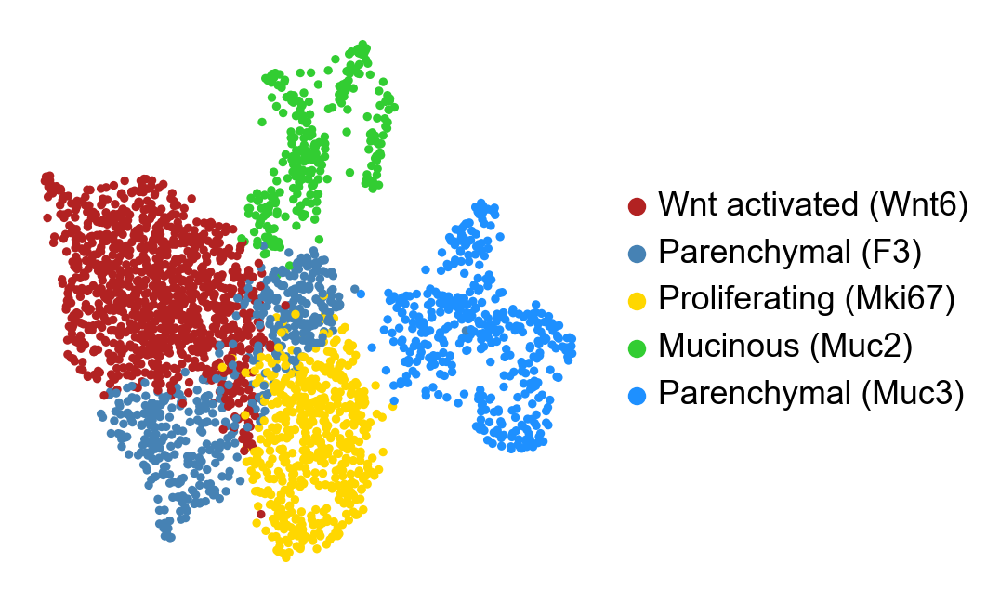

In [3]:
sc.pl.umap(adata, color=['leiden'], legend_loc='right margin', frameon=False, title='', use_raw=False)

In [4]:
scv.utils.show_proportions(adata)

Abundance of ['spliced', 'unspliced']: [0.73 0.27]


In [5]:
# 1. Compute terminal states (backward=False)

In [6]:
# 1.1 Initialize 1st kernel and compute a transition matrix
vk = cr.tl.kernels.VelocityKernel(adata, backward=False).compute_transition_matrix()
adata

Computing transition matrix based on logits using `'deterministic'` mode
Estimating `softmax_scale` using `'deterministic'` mode


  0%|          | 0/2642 [00:00<?, ?cell/s]

Setting `softmax_scale=1.5106`


  0%|          | 0/2642 [00:00<?, ?cell/s]

    Finish (0:00:01)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    o

In [7]:
# 1.2 Initialize an estimator
g_fwd = cr.tl.estimators.GPCCA(vk)
adata

AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    o

Computing Schur decomposition
When computing macrostates, choose a number of states NOT in `[5, 11, 13, 19]`
Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:06)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params', 'sch

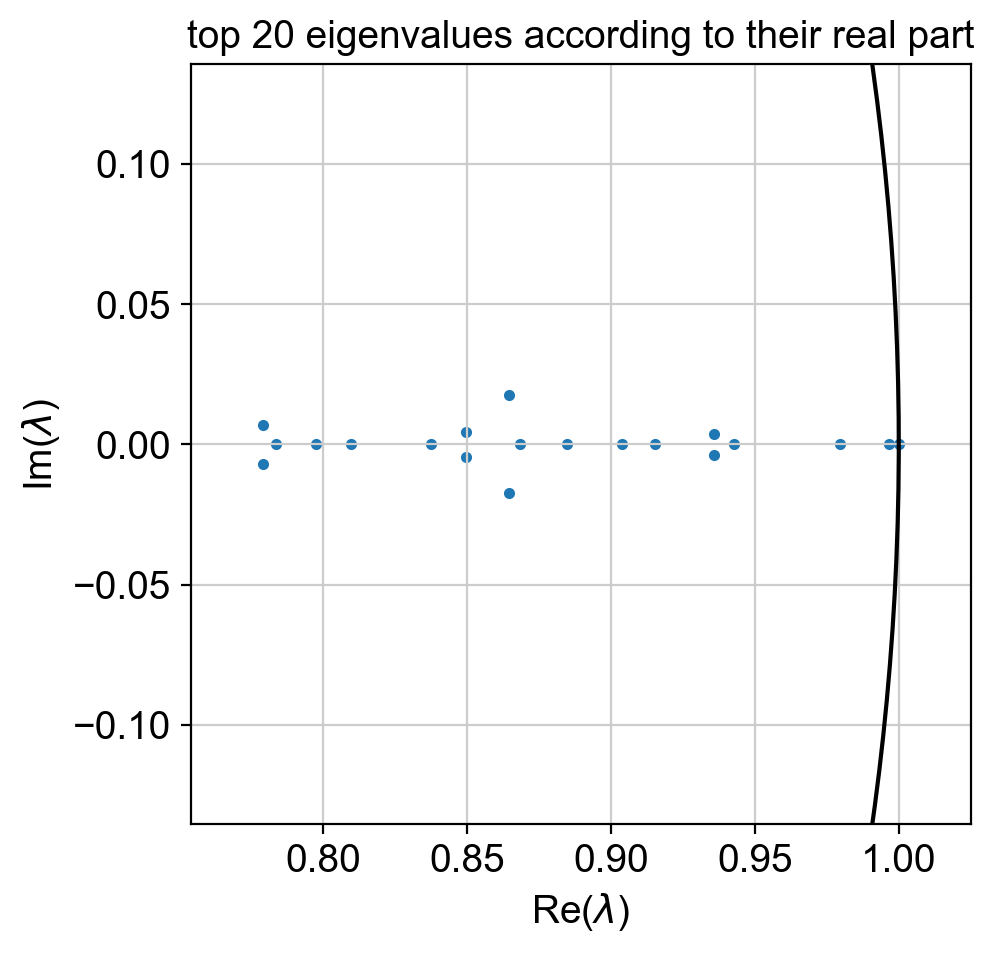

In [8]:
# 1.3 Compute a matrix decomposition
g_fwd.compute_schur(n_components=20, method='brandts')
g_fwd.plot_spectrum()
adata

In [9]:
# 1.4 Compute macrostates
g_fwd.compute_macrostates(n_states=3, n_cells=30, cluster_key="leiden")
# n_states= determines how many macrostates to calculate, n_cells= determines top n driver cells in each state
# n_states set here will affect all the downstream analysis, like the directed-PAGA arrows and gene trends. It's important to optimize n_states.
adata
# these codes return
# uns: 'coarse_fwd'

Computing `3` macrostates
Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:00)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params', 'sch

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


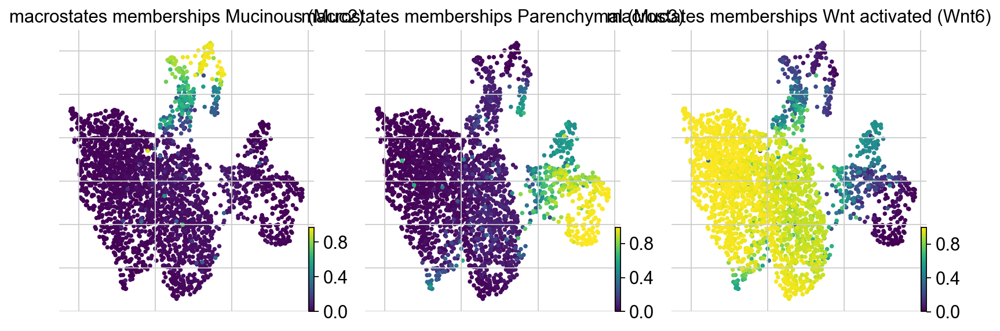

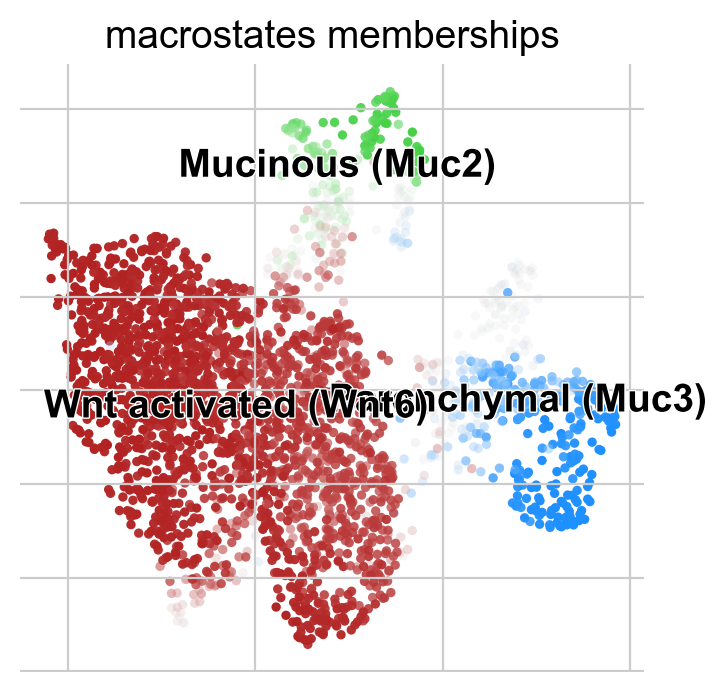

In [10]:
# plot individual macrostates
g_fwd.plot_macrostates(same_plot=False)
# plot merged macrostates
g_fwd.plot_macrostates(same_plot=True)

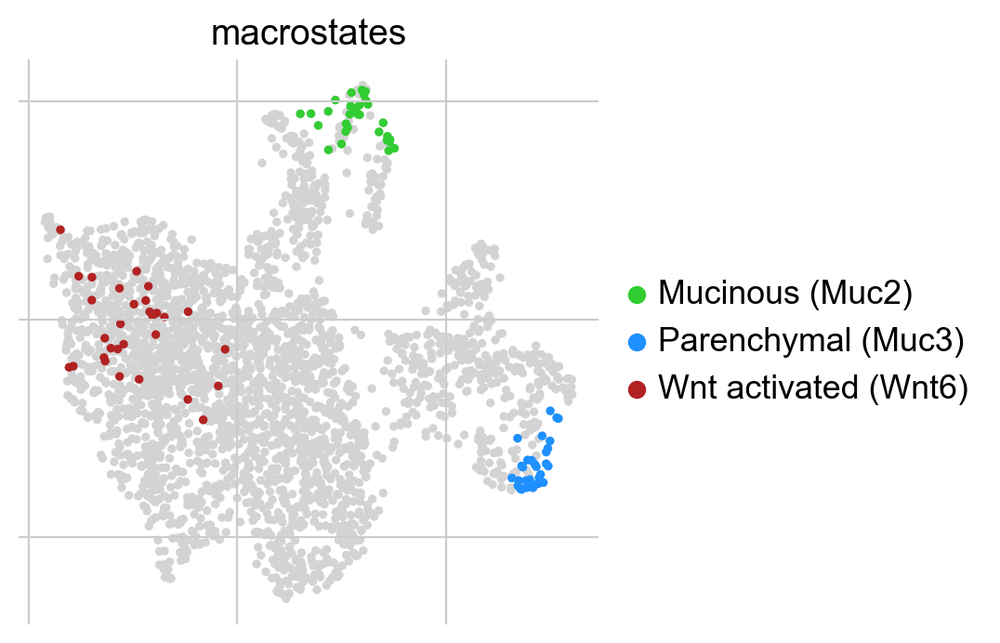

In [11]:
# locate the top30 driver cells for each cluster, set discrete=True in g.plot_macrostates(), but need to set n_cells=30 in g.compute_macrostates()
g_fwd.plot_macrostates(discrete=True, legend_loc="right", basis="umap")

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\cellrank\tl\estimators\terminal_states\_gpcca.py:613: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  _ = ColorbarBase(


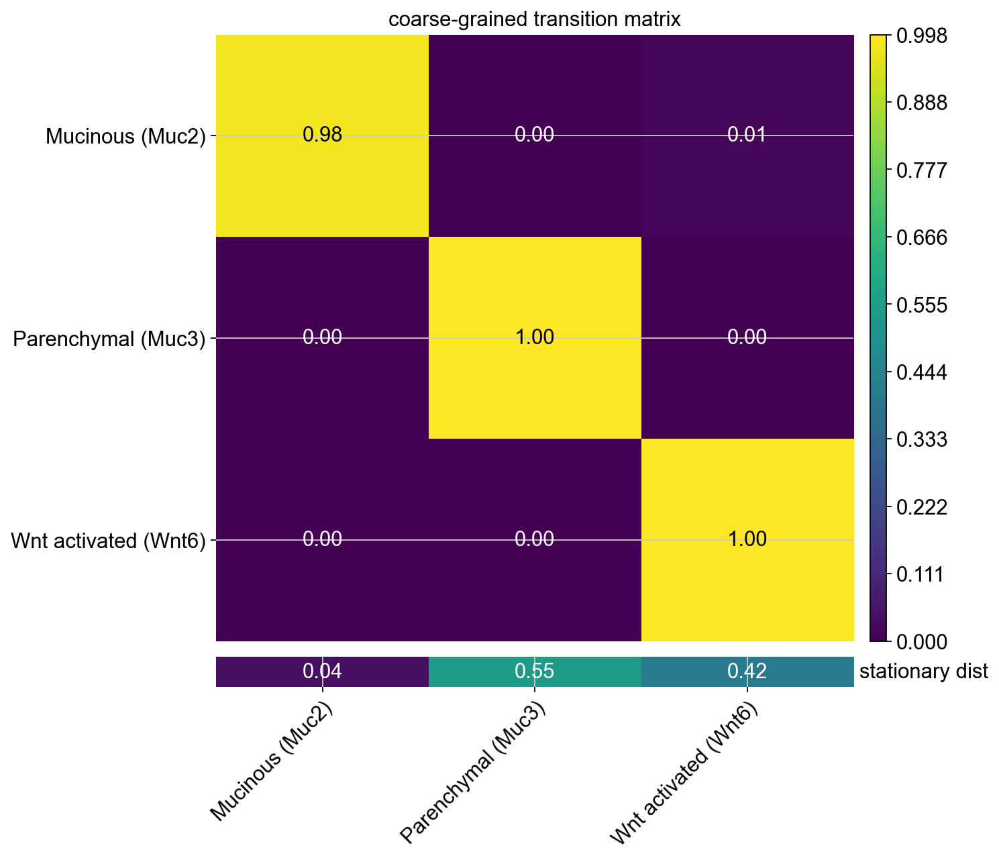

In [12]:
g_fwd.plot_coarse_T()

In [13]:
# 1.5 set the terminal state from the macrostates
g_fwd.set_terminal_states_from_macrostates(names=['Wnt activated (Wnt6)', 'Mucinous (Muc2)', 'Parenchymal (Muc3)'])    # this is automatic way, we can set terminal state manually by below functions
# different ways to set the terminal state:
    # g_fwd.compute_terminal_states(): automatically selects the terminal states from the set of macrostates via a stability criterion.
    # g_fwd.set_terminal_states_from_macrostates(): manually restrict the macrostates by passing a list of macrostate-names that you know are terminal in your data.
    # g_fwd.set_terminal_states(): manually set the terminal states, without computing macrostates, entirely manually.
adata
# these codes return
# obs: 'clusters_gradients', 'terminal_states', 'terminal_states_probs'
# uns: 'clusters_gradients_colors', 'terminal_states_colors'
# obsm: 'terminal_states_memberships'

Adding `adata.obs['terminal_states']`
       `adata.obs['terminal_states_probs']`
       `.terminal_states`
       `.terminal_states_probabilities`
       `.terminal_states_memberships
    Finish`


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics

In [14]:
adata.obs['terminal_states']

AAACCCAAGTCGAAGC                   NaN
AAACCCACAGCGCGTT                   NaN
AAACCCATCGTTCATT                   NaN
AAACGAAGTACCTGTA                   NaN
AAACGAAGTAGATTAG                   NaN
                           ...        
TTTGGTTTCCGCGATG                   NaN
TTTGGTTTCTGCTCTG    Parenchymal (Muc3)
TTTGTTGAGGGCCTCT                   NaN
TTTGTTGGTCAGTCTA                   NaN
TTTGTTGGTCGGTGTC                   NaN
Name: terminal_states, Length: 2642, dtype: category
Categories (3, object): ['Wnt activated (Wnt6)', 'Mucinous (Muc2)', 'Parenchymal (Muc3)']

In [15]:
# 1.6 Estimate fate probabilities
# after setting the terminal state, we can compute fate probabilities towards them
g_fwd.compute_absorption_probabilities(n_jobs=16)
adata
# these codes return
# obsm: 'to_terminal_states'

Computing absorption probabilities
Defaulting to `'gmres'` solver.


  0%|          | 0/3 [00:00<?, ?/s]

Adding `adata.obsm['to_terminal_states']`
       `.absorption_probabilities`
    Finish (0:00:05)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


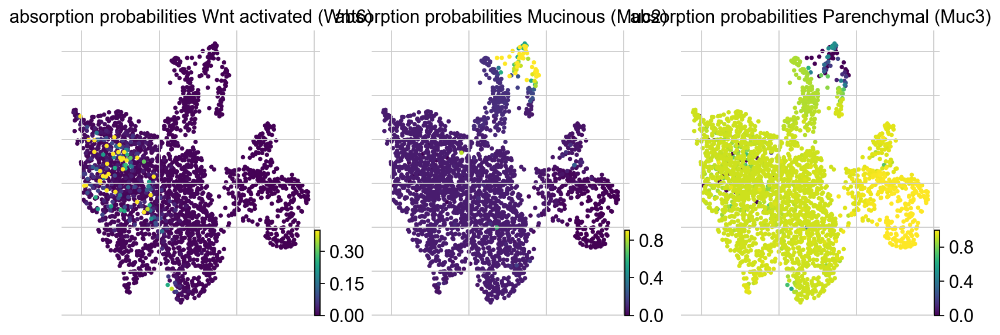

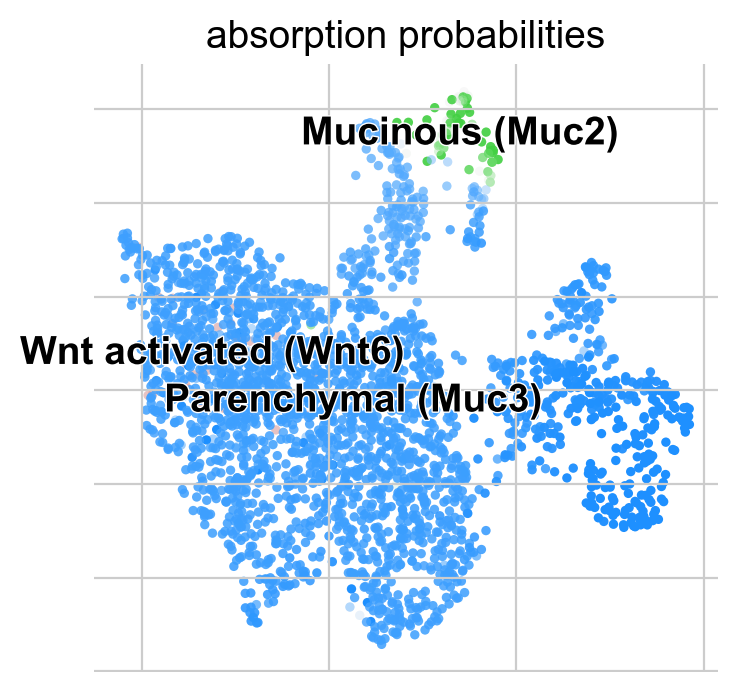

In [16]:
# plot fate probabilities
g_fwd.plot_absorption_probabilities(same_plot=False, basis="umap")
g_fwd.plot_absorption_probabilities(same_plot=True, basis="umap")

In [17]:
# 1.7 Find lineage driver genes for terminal states
# Terminal states should be determined in advance, and g_fwd.compute_absorption_probabilities should be run. Then we can run g_fwd.compute_lineage_drivers(), which calculates lineage driver genes for terminal states.
g_fwd.compute_lineage_drivers(lineages=['Wnt activated (Wnt6)', 'Mucinous (Muc2)', 'Parenchymal (Muc3)'], return_drivers=True)    # if use kernal and estimator, calculate lineage driver genes by estimator.compute_lineage_drivers(), not cr.tl.lineage_drivers()
# the lineage dirve genes of cluster 'Alpha' will be sorted by 'Alpha_corr'
# this step is required for drawing gene trends later

Adding `adata.varm['terminal_lineage_drivers']`
       `.lineage_drivers`
    Finish (0:00:00)


,Wnt activated (Wnt6)_corr,Wnt activated (Wnt6)_pval,Wnt activated (Wnt6)_qval,Wnt activated (Wnt6)_ci_low,Wnt activated (Wnt6)_ci_high,Mucinous (Muc2)_corr,Mucinous (Muc2)_pval,Mucinous (Muc2)_qval,Mucinous (Muc2)_ci_low,Mucinous (Muc2)_ci_high,Parenchymal (Muc3)_corr,Parenchymal (Muc3)_pval,Parenchymal (Muc3)_qval,Parenchymal (Muc3)_ci_low,Parenchymal (Muc3)_ci_high
Mt3,0.272308,1.053016e-46,2.106032e-43,0.236631,0.307252,-0.045915,1.825719e-02,7.638991e-02,-0.083902,-0.007794,-0.151649,4.128953e-15,9.602216e-14,-0.188692,-0.114175
Vim,0.237065,2.180866e-35,2.180866e-32,0.200746,0.272734,-0.027305,1.606074e-01,4.150063e-01,-0.065371,0.010841,-0.141966,2.095380e-13,4.276286e-12,-0.179131,-0.104397
Wif1,0.222438,3.216867e-31,2.144578e-28,0.185880,0.258381,-0.035026,7.185428e-02,2.310427e-01,-0.073062,0.003113,-0.125837,8.095020e-11,1.360508e-09,-0.163188,-0.088125
Mt4,0.206271,5.884248e-27,2.942124e-24,0.169470,0.242498,-0.041204,3.418479e-02,1.273177e-01,-0.079214,-0.003074,-0.109831,1.470082e-08,1.860864e-07,-0.147349,-0.071998
Fth1,0.198930,3.875616e-25,1.464122e-22,0.162024,0.235279,0.134267,3.939023e-12,6.203186e-11,0.096627,0.171523,-0.242406,5.504917e-37,2.752459e-35,-0.277971,-0.206178
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Malat1,-0.133409,5.406021e-12,5.406021e-10,-0.170675,-0.095762,-0.034524,7.601926e-02,2.405673e-01,-0.072563,0.003615,0.119012,8.102532e-10,1.174280e-08,0.081246,0.156437
Neat1,-0.140880,3.201430e-13,3.766389e-11,-0.178058,-0.103301,0.086227,8.969495e-06,7.262749e-05,0.048252,0.123954,0.029443,1.302878e-01,2.810955e-01,-0.008701,0.067502
Ceacam1,-0.144583,7.443654e-14,9.924872e-12,-0.181715,-0.107038,0.078633,5.169385e-05,3.843409e-04,0.040620,0.116418,0.037985,5.090262e-02,1.431109e-01,-0.000149,0.076010
Pigr,-0.146095,4.055861e-14,5.794088e-12,-0.183209,-0.108566,0.077585,6.505692e-05,4.731412e-04,0.039568,0.115378,0.039861,4.048074e-02,1.183647e-01,0.001729,0.077877


C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


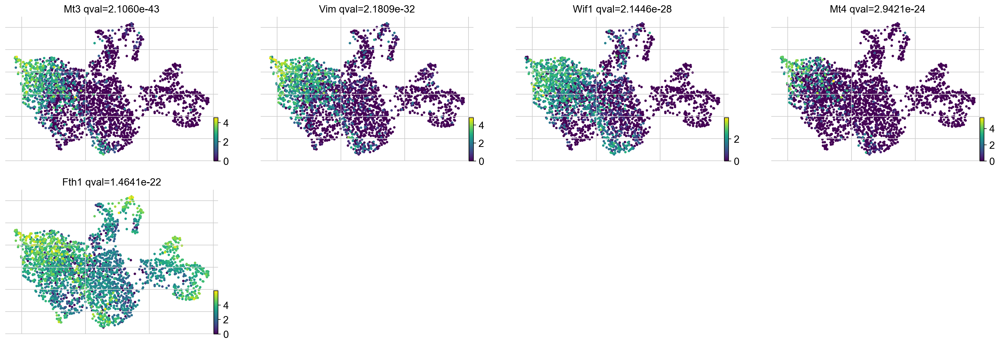

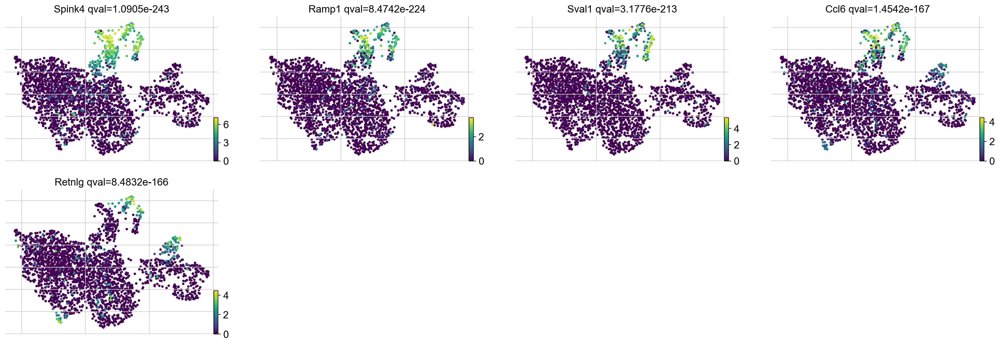

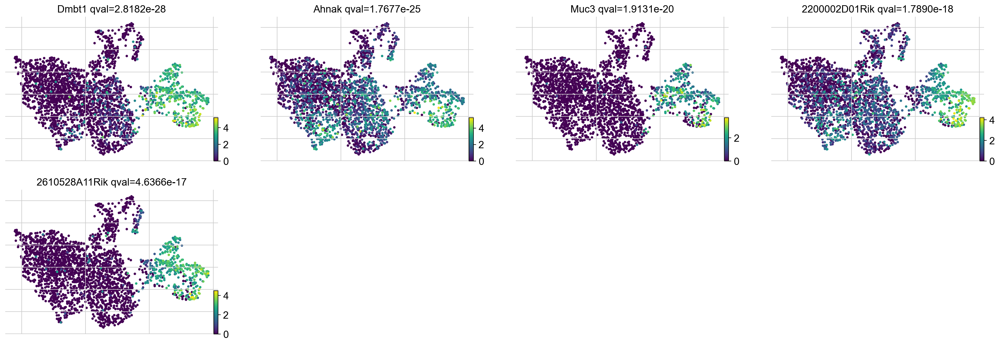

In [18]:
# plot top5 lineage drivers
g_fwd.plot_lineage_drivers(lineage='Wnt activated (Wnt6)', n_genes=5)
g_fwd.plot_lineage_drivers(lineage='Mucinous (Muc2)', n_genes=5)
g_fwd.plot_lineage_drivers(lineage='Parenchymal (Muc3)', n_genes=5)

In [19]:
# 2. Compute initial states (backward=True)
# if computing terminal states already determines the right initial states, you can skip this Step 2

In [20]:
# 2.1 Initialize combined kernels and compute a transition matrix
vk = cr.tl.kernels.VelocityKernel(adata, backward=True).compute_transition_matrix()
adata

Computing transition matrix based on logits using `'deterministic'` mode
Estimating `softmax_scale` using `'deterministic'` mode


  0%|          | 0/2642 [00:00<?, ?cell/s]

Setting `softmax_scale=1.5106`


  0%|          | 0/2642 [00:00<?, ?cell/s]

    Finish (0:00:01)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics

In [21]:
# 2.2 Initialize an estimator
g_bwd = cr.tl.estimators.GPCCA(vk)
adata

AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics

Computing Schur decomposition
When computing macrostates, choose a number of states NOT in `[6, 8, 10, 13, 15]`
Adding `adata.uns['eigendecomposition_bwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:06)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics

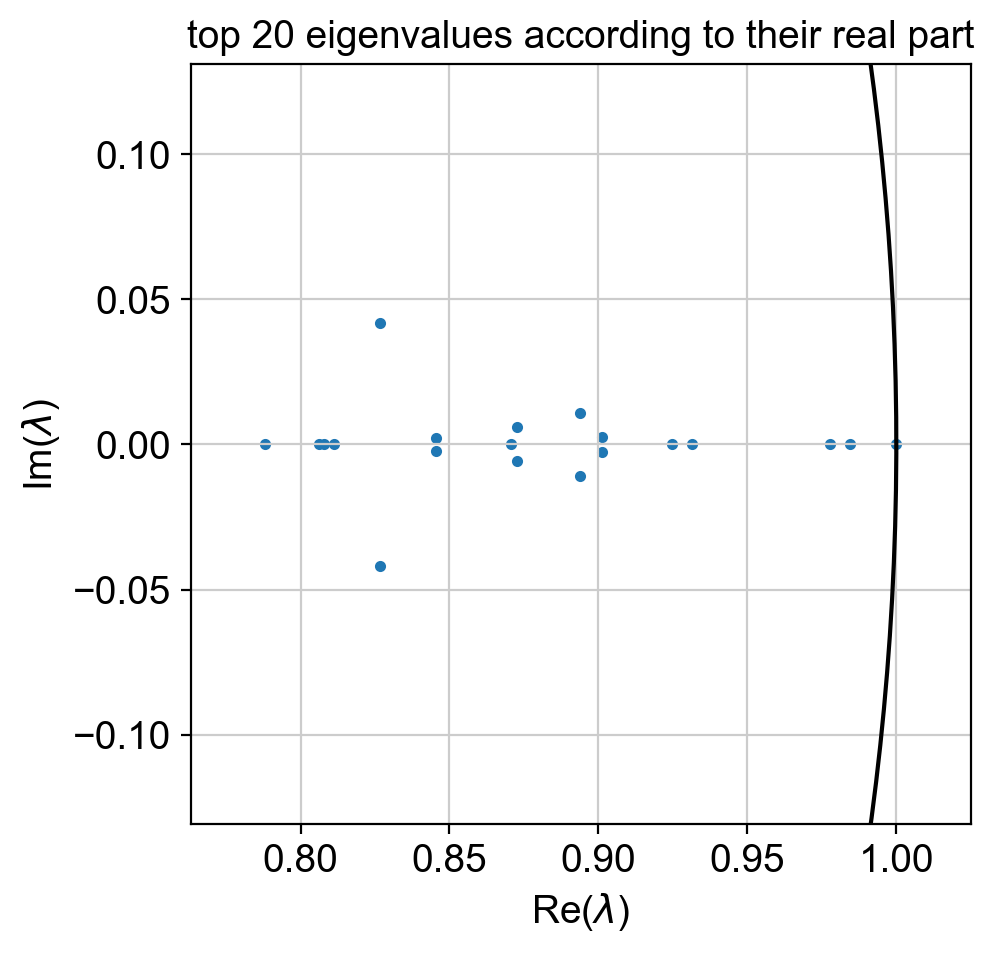

In [22]:
# 2.3 Compute a matrix decomposition
g_bwd.compute_schur(n_components=20, method='brandts')
g_bwd.plot_spectrum()
adata

In [23]:
## g_bwd.compute_eigendecomposition()    # run this if only 1 state was determined, which shows RuntimeError: No stationary distribution found in `.eigendecomposition['stationary_dist']`

In [24]:
# 2.4 Compute macrostates
g_bwd.compute_macrostates(n_states=1, n_cells=30, cluster_key="leiden")
# n_states= determines how many macrostates to calculate, n_cells= determines top n driver cells in each state
# n_states set here will affect all the downstream analysis, like the directed-PAGA arrows and gene trends. For example, set n_states=3 here for computing initial states will make arrows starting form 'Ngn3 low EP' all disappear. So it's important to optimize n_states.
adata
# these codes return
# uns: 'coarse_fwd'

For 1 macrostate, stationary distribution is computed
Computing eigendecomposition of the transition matrix
Adding `adata.uns['eigendecomposition_bwd']`
       `.eigendecomposition`
    Finish (0:00:00)
Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:00)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes', 'recover_dynamics

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


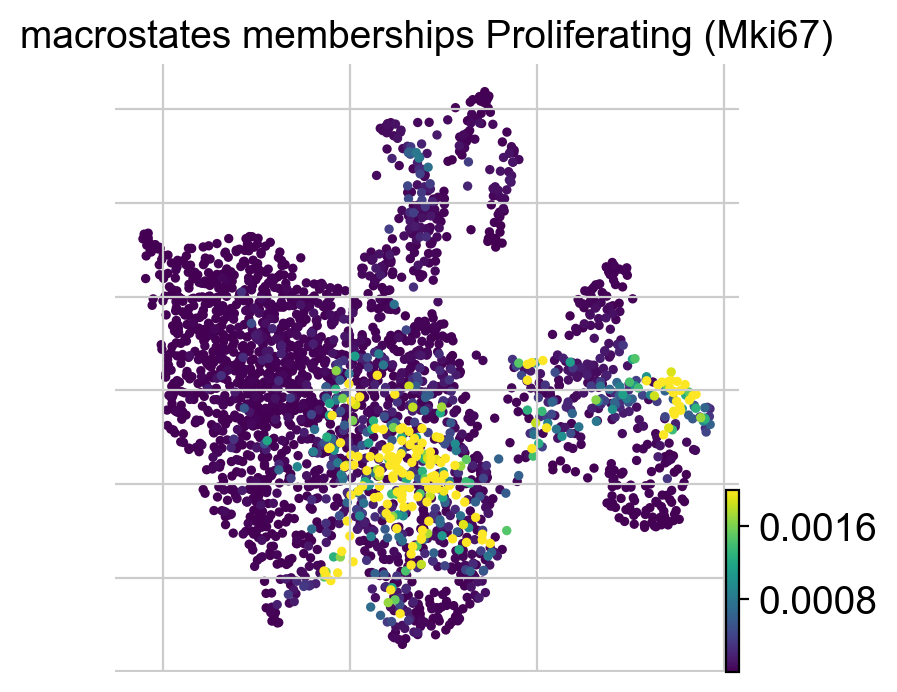

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


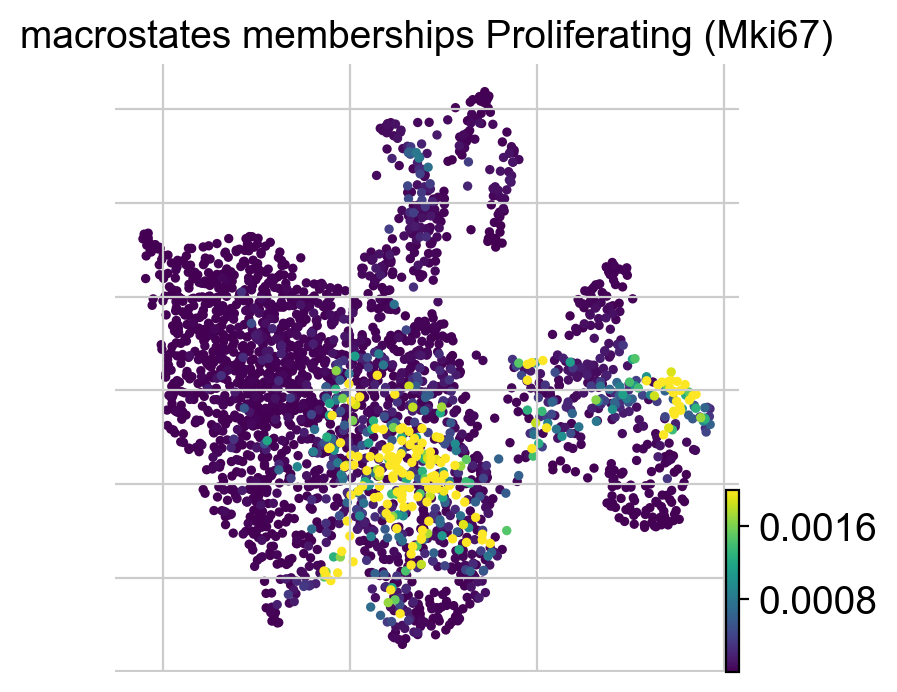

In [25]:
# plot individual macrostates
g_bwd.plot_macrostates(same_plot=False)
# plot merged macrostates
g_bwd.plot_macrostates(same_plot=True)

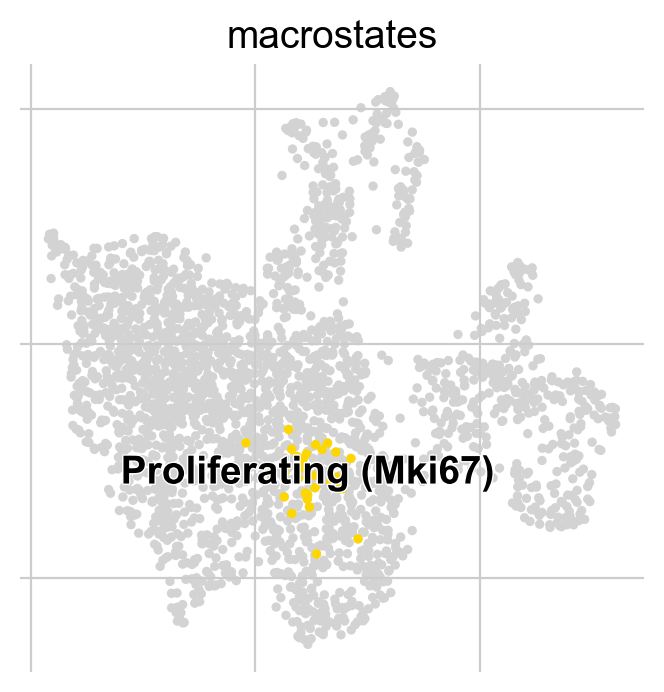

In [26]:
# locate the top30 driver cells for each cluster, set discrete=True in g.plot_macrostates(), but need to set n_cells=30 in g.compute_macrostates()
g_bwd.plot_macrostates(discrete=True)

In [27]:
## g_bwd.plot_coarse_T()    # only can plot when n_states > 1

In [28]:
# 2.5 set the initial state from the macrostates
g_bwd.set_terminal_states(labels={'leiden': ['Proliferating (Mki67)']})    # this is automatic way, we can set initial state manually by below functions
# different ways to set the initial state:
    # g_bwd.compute_terminal_states(): automatically selects the initial states from the set of macrostates via a stability criterion.
    # g_bwd.set_terminal_states_from_macrostates(): manually restrict the macrostates by passing a list of macrostate-names that you know are initial in your data.
    # g_bwd.set_terminal_states(): manually set the initial states, without computing macrostates, entirely manually.
adata
# these codes return
# obs: 'clusters_gradients', 'initial_states', 'initial_states_probs'
# uns: 'clusters_gradients_colors', 'initial_states_colors'
# obsm: 'initial_states_memberships'

Adding `adata.obs['initial_states']`
       `adata.obs['initial_states_probs']`
       `.terminal_states`
       `.terminal_states_probabilities`
       `.terminal_states_memberships
    Finish`


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs', 'initial_states'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes',

In [29]:
adata.obs['initial_states']

AAACCCAAGTCGAAGC                      NaN
AAACCCACAGCGCGTT                      NaN
AAACCCATCGTTCATT                      NaN
AAACGAAGTACCTGTA                      NaN
AAACGAAGTAGATTAG                      NaN
                            ...          
TTTGGTTTCCGCGATG    Proliferating (Mki67)
TTTGGTTTCTGCTCTG                      NaN
TTTGTTGAGGGCCTCT                      NaN
TTTGTTGGTCAGTCTA                      NaN
TTTGTTGGTCGGTGTC                      NaN
Name: initial_states, Length: 2642, dtype: category
Categories (1, object): ['Proliferating (Mki67)']

In [30]:
# 2.6 Estimate fate probabilities
g_bwd.compute_absorption_probabilities(n_jobs=16)
adata
# these codes return
# obsm: 'from_initial_states'

Computing absorption probabilities


  0%|          | 0/1 [00:00<?, ?/s]

Adding `adata.obsm['from_initial_states']`
       `.absorption_probabilities`
    Finish (0:00:00)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs', 'initial_states'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes',

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


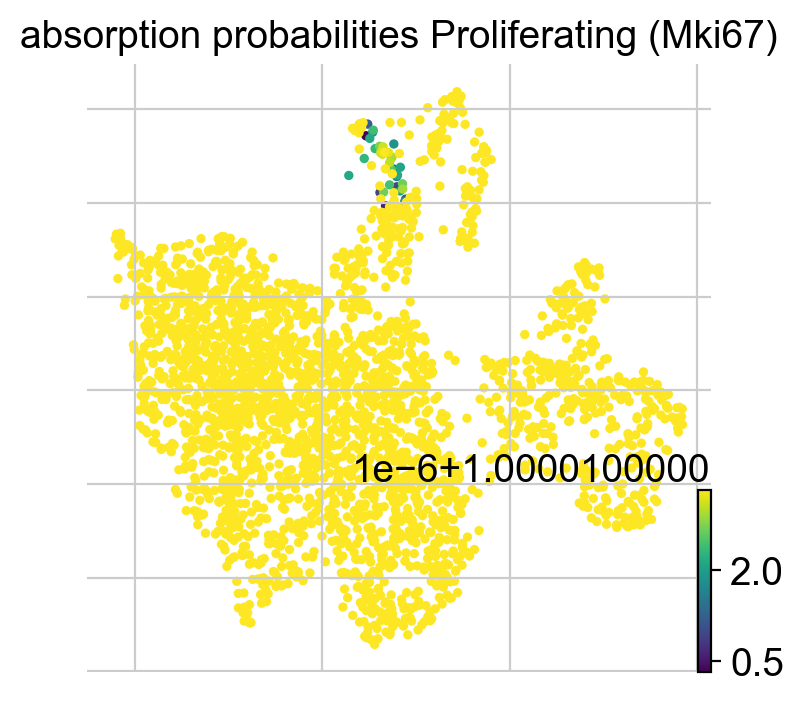

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


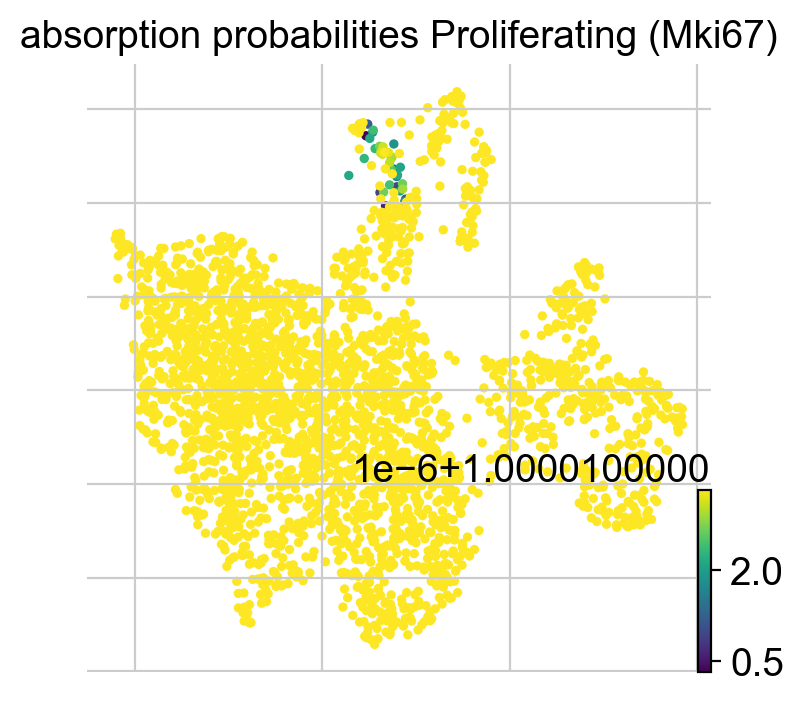

In [31]:
# plot fate probabilities
g_bwd.plot_absorption_probabilities(same_plot=False, basis="umap")
g_bwd.plot_absorption_probabilities(same_plot=True, basis="umap")

In [32]:
# 2.7 Find lineage driver genes for initial states
# Initial states should be determined in advance, and g_bwd.compute_absorption_probabilities should be run. Then we can run g_bwd.compute_lineage_drivers(), which calculates lineage driver genes for initial states.
g_bwd.compute_lineage_drivers(lineages="Proliferating (Mki67)", return_drivers=True)    # if use kernal and estimator, calculate lineage driver genes by estimator.compute_lineage_drivers(), not cr.tl.lineage_drivers()
# the lineage dirve genes of cluster 'Ngn3 low EP' will be sorted by 'Ngn3 low EP_corr'
# this step is required for drawing gene trends later

Adding `adata.varm['initial_lineage_drivers']`
       `.lineage_drivers`
    Finish (0:00:00)


,Proliferating (Mki67)_corr,Proliferating (Mki67)_pval,Proliferating (Mki67)_qval,Proliferating (Mki67)_ci_low,Proliferating (Mki67)_ci_high
H2afz,0.266898,7.586376e-45,7.586376e-42,0.231116,0.301959
Ly6a,0.247117,1.983714e-38,9.918570e-36,0.210970,0.282588
Lgals4,0.232127,6.022412e-34,2.408965e-31,0.195725,0.267890
Crip1,0.225269,5.296700e-32,1.765567e-29,0.188756,0.261160
Mgst3,0.222895,2.408197e-31,6.880564e-29,0.186345,0.258830
...,...,...,...,...,...
Tcf4,-0.164158,1.739333e-17,2.319111e-15,-0.201034,-0.126818
Gm26917,-0.170203,1.051932e-18,1.618357e-16,-0.206994,-0.132931
Lars2,-0.219127,2.568153e-30,6.420381e-28,-0.255129,-0.182518
Neat1,-0.251370,9.256821e-40,6.171214e-37,-0.286756,-0.215299


C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scvelo\plotting\utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)


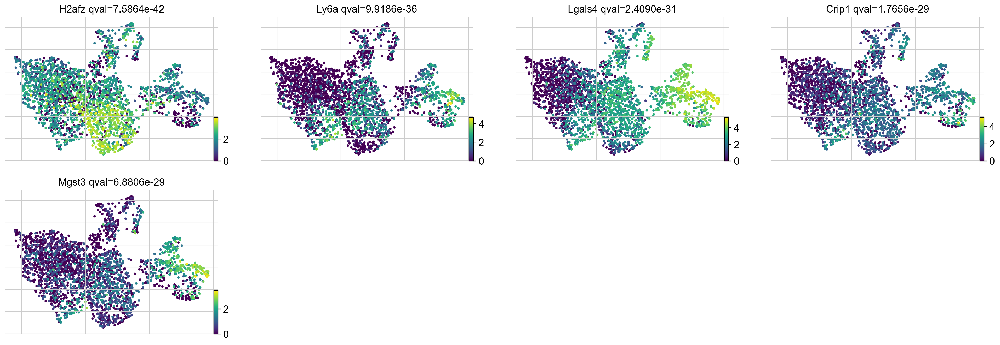

In [33]:
# plot top5 lineage drivers
g_bwd.plot_lineage_drivers(lineage="Proliferating (Mki67)", n_genes=5)

In [34]:
# 3. Fate-probability-directed PAGA= pseudotime-directed PAGA + CellRank determined inistial and terminal states

# Step 1: compute initial states and terminal states

# Step 2: generate a pseudotime
    # DPT pseudotime
        # after computing initial states by cr.tl.initial_states()
            ## adata.obs["initial_states"]
            ## root_idx = np.where(adata.obs["initial_states"] == "Ngn3 low EP")[0][0]
            ## adata.uns["iroot"] = root_idx
            ## sc.tl.dpt(adata)
        # generates adata.obs['dpt_pseudotime']
        # or
        # set the root cluster manually
            ## root_idx = np.flatnonzero(adata.obs['paul15_clusters']  == '8Mk')[0]
            ## adata.uns['iroot'] = root_idx
            ## sc.tl.dpt(adata)
        # generates adata.obs['dpt_pseudotime']
    # Velocity pseudotime
        # scv.tl.velocity_pseudotime(adata) in scVelo generates adata.obs['velocity_pseudotime']
    # Latent time
        # scv.tl.latent_time(adata) in scVelo generates adata.obs['velocity_pseudotime'] and adata.obs['latent_time']
        # if you already run scv.tl.latent_time(adata) in scVelo, and dont want to combine with the information of CellRank determined inistal states and terminal states, no need to run scv.tl.recover_latent_time() here
        # if you didnt run scv.tl.latent_time(adata) in scVelo, you can run scv.tl.recover_latent_time(adata, vkey='velocity') here to generate adata.obs['latent_time']
        # if you want to generate adata.obs['latent_time'] combined with the information of CellRank determined inistal states and terminal states, run scv.tl.recover_latent_time(adata, vkey='velocity', root_key="initial_states_probs", end_key="terminal_states_probs") here
    # CytoTRACE pseudotime
        # CytoTRACEKernel(adata) in CellRank generates adata.obs['ct_pseudotime']

# Step 3: plot fate-probability-directed PAGA
    # DPT pseudotime
        # scv.tl.paga(adata, groups='clusters', vkey='velocity', use_time_prior="dpt_pseudotime"), without using the information of CellRank determined inistal states and terminal states, so this is just pseudotime-directed PAGA
        # recommend scv.tl.paga(adata, groups='clusters', vkey='velocity', use_time_prior="dpt_pseudotime", root_key="initial_states_probs", end_key="terminal_states_probs"), so this is the real fate-probability-directed PAGA
    # Velocity pseudotime
        # scv.tl.paga(adata, groups='clusters', vkey='velocity', use_time_prior="velocity_pseudotime")
        # recommend scv.tl.paga(adata, groups='clusters', vkey='velocity', use_time_prior="velocity_pseudotime", root_key="initial_states_probs", end_key="terminal_states_probs")
    # Latent time
        # scv.tl.paga(adata, groups='clusters', vkey='velocity', use_time_prior="latent_time")
        # recommend scv.tl.paga(adata, groups='clusters', vkey='velocity', use_time_prior="latent_time", root_key="initial_states_probs", end_key="terminal_states_probs")
    # CytoTRACE pseudotime
        # scv.tl.paga() calls adata.uns['velocity_graph'] to draw directed PAGA, becasue scVelo generates adata.uns['velocity_graph'], but CytoTRACE kernal doesnt, so
        # adata.uns['velocity_graph'] = adata.obsp['connectivities']
        # scv.tl.paga(adata, groups='clusters', vkey='velocity', use_time_prior="ct_pseudotime", root_key="initial_states_probs", end_key="terminal_states_probs")
    # then scv.pl.paga(adata, basis='umap')

In [35]:
scv.tl.recover_latent_time(adata, vkey='velocity', root_key="initial_states_probs", end_key="terminal_states_probs")
# this latent_time combines the information of CellRank determined inistal states and terminal states
adata
# these codes return
# obs: 'velocity_pseudotime', 'latent_time'

computing latent time using root_cells, terminal_states_probs as prior
    finished (0:00:00) --> added 
    'latent_time', shared time (adata.obs)


AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs', 'initial_states'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes',

running PAGA using priors: ['latent_time', 'terminal_states_probs']
    finished (0:00:00) --> added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns)
    'paga/transitions_confidence', velocity transitions (adata.uns)


C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\networkx\drawing\nx_pylab.py:717: MatplotlibDeprecationWarning: Passing *transOffset* without *offsets* has no effect. This behavior is deprecated since 3.5 and in 3.6, *transOffset* will begin having an effect regardless of *offsets*. In the meantime, if you wish to set *transOffset*, call collection.set_offset_transform(transOffset) explicitly.
  edge_collection = mpl.collections.LineCollection(


Consider running `set_figure_params(dpi_save=...)`, which will adjust `matplotlib.rcParams['savefig.dpi']`
saving figure to file ./figures/scvelo_1.svg


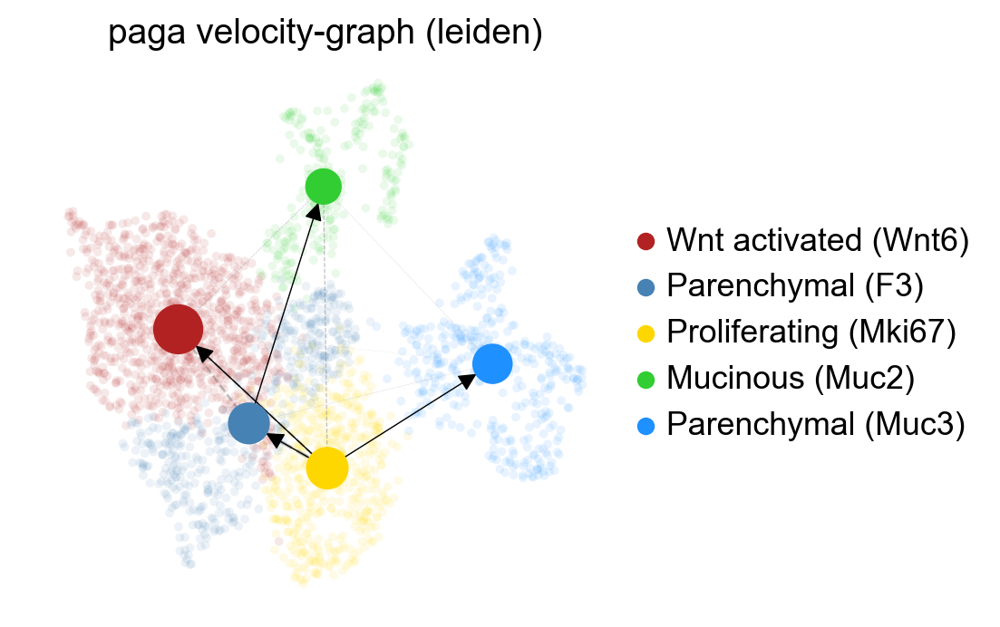

AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs', 'initial_states'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes',

In [36]:
# set root_key="initial_states_probs", end_key="terminal_states_probs" to make directed PAGA consistent with CellRank determined inistal states and terminal states
scv.tl.paga(adata, groups='leiden', vkey='velocity', use_time_prior="latent_time", root_key="initial_states_probs", end_key="terminal_states_probs")
scv.pl.paga(adata, basis='umap', vkey='velocity', color='leiden', size=50, alpha=0.1, min_edge_width=0.5, node_size_scale=1.5, use_raw=False, save='1.svg')
adata
# these codes return
# var: 'paga', 'clusters_sizes'

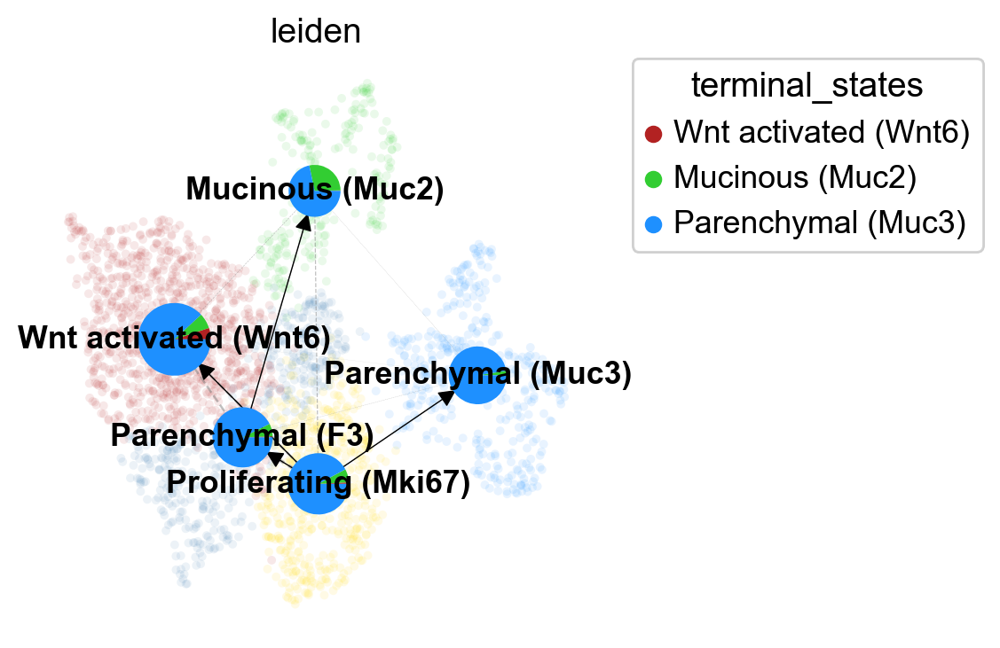

In [37]:
cr.pl.cluster_fates(adata, mode="paga_pie", cluster_key="leiden", basis="umap",
                    legend_kwargs={"loc": "top right out"}, size=50, alpha=0.1, min_edge_width=0.5, node_size_scale=3, use_raw=False, save='2.pdf')

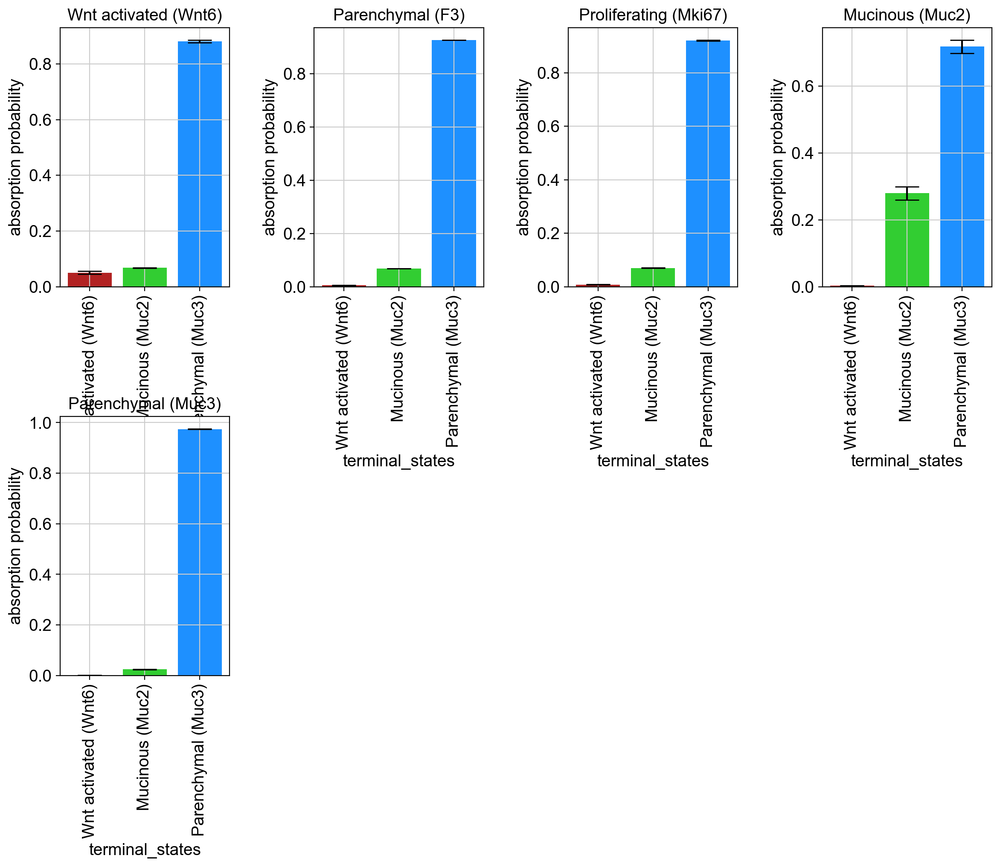

In [38]:
# 4. Aggregated cellular fates, the whiskers correspond to the standard error of the mean.
# 4.1 Aggregated cellular fates for terminal states (backward=False)
cr.pl.cluster_fates(adata, mode="bar", backward=False, cluster_key="leiden")

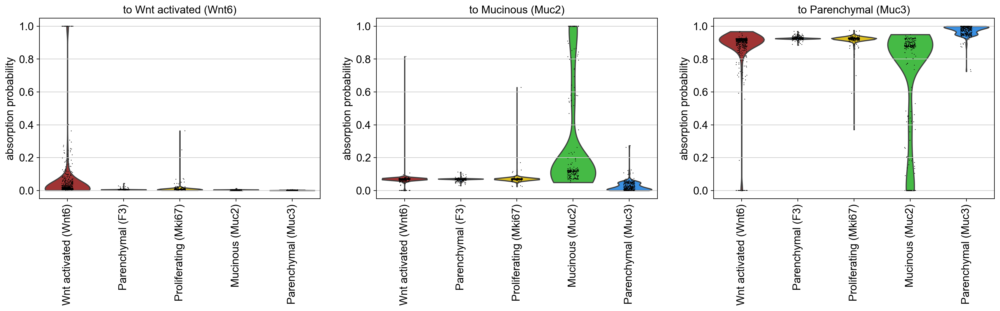

In [39]:
cr.pl.cluster_fates(adata, mode="violin", backward=False, cluster_key="leiden")

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\seaborn\matrix.py:302: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  mesh = ax.pcolormesh(self.plot_data, cmap=self.cmap, **kws)
C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\seaborn\matrix.py:312: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = ax.figure.colorbar(mesh, cax, ax, **self.cbar_kws)


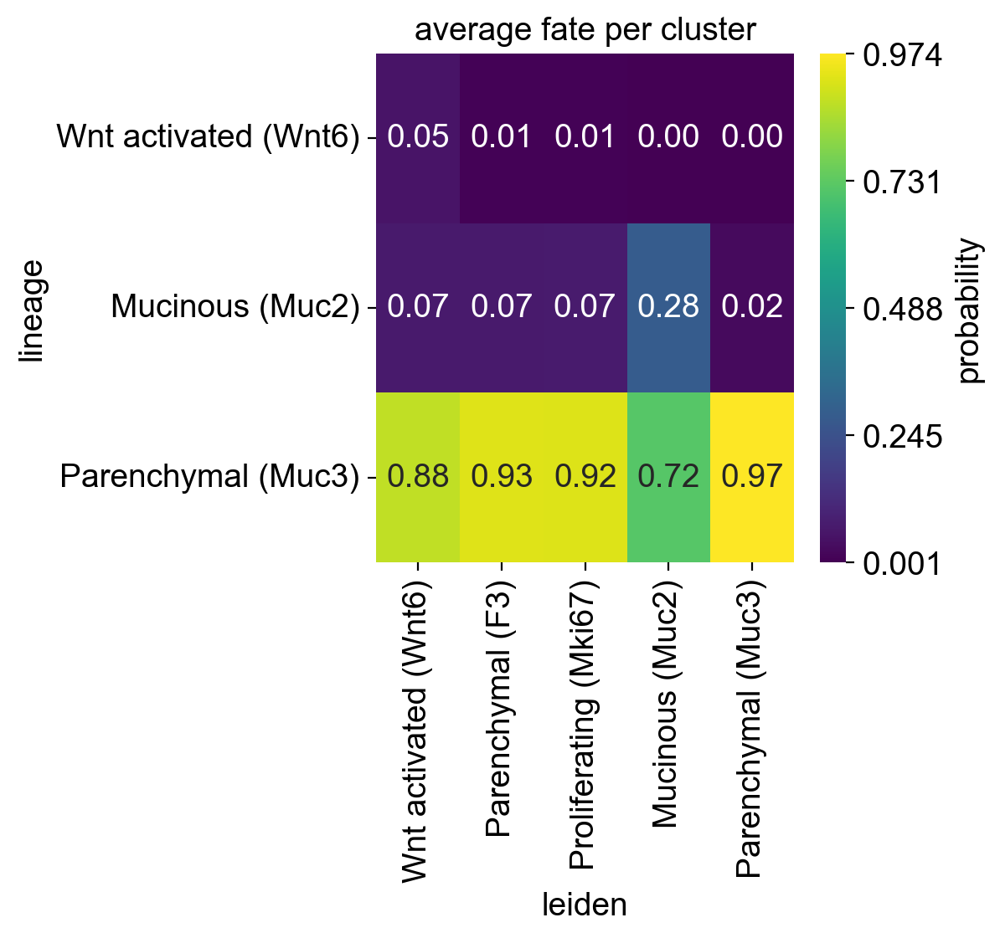

In [40]:
cr.pl.cluster_fates(adata, mode="heatmap", backward=False, cluster_key="leiden")

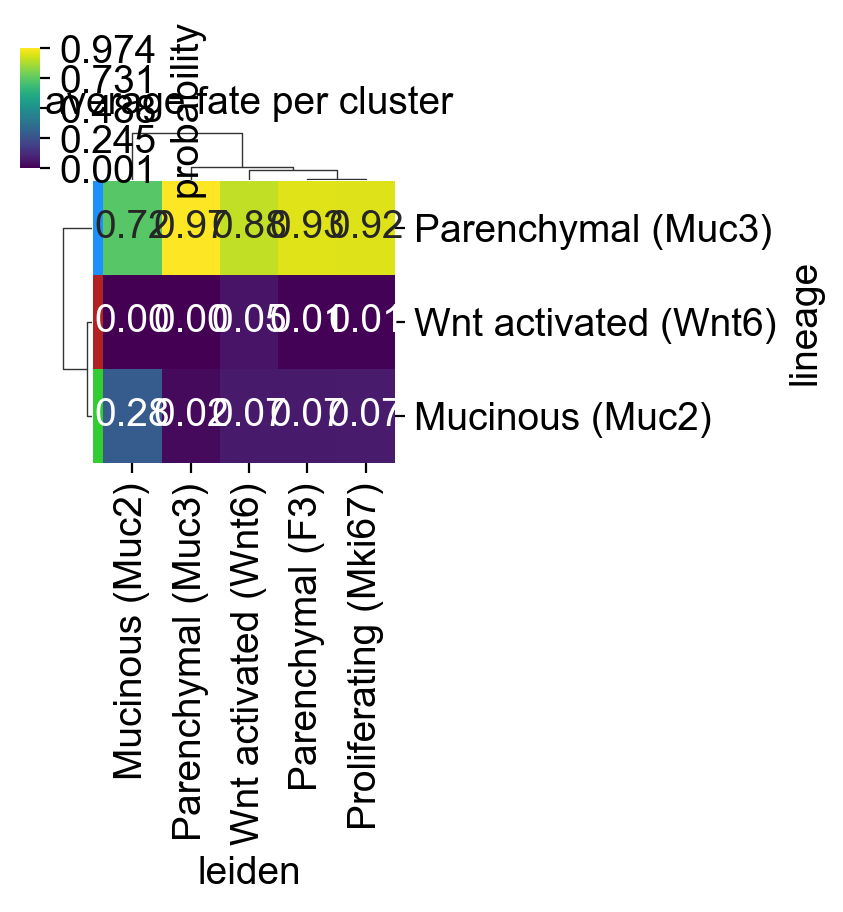

In [41]:
cr.pl.cluster_fates(adata, mode="clustermap", backward=False, cluster_key="leiden")

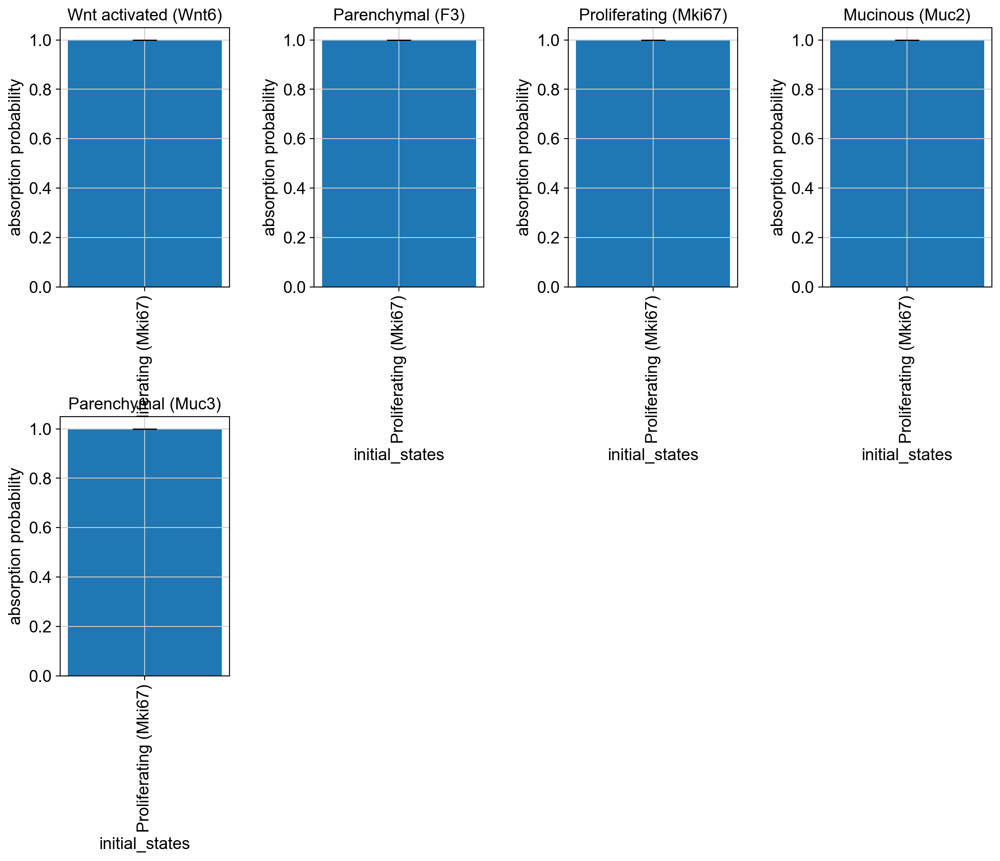

In [42]:
# 4.2 Aggregated cellular fates for initial states (backward=True)
cr.pl.cluster_fates(adata, mode="bar", backward=True, cluster_key="leiden")

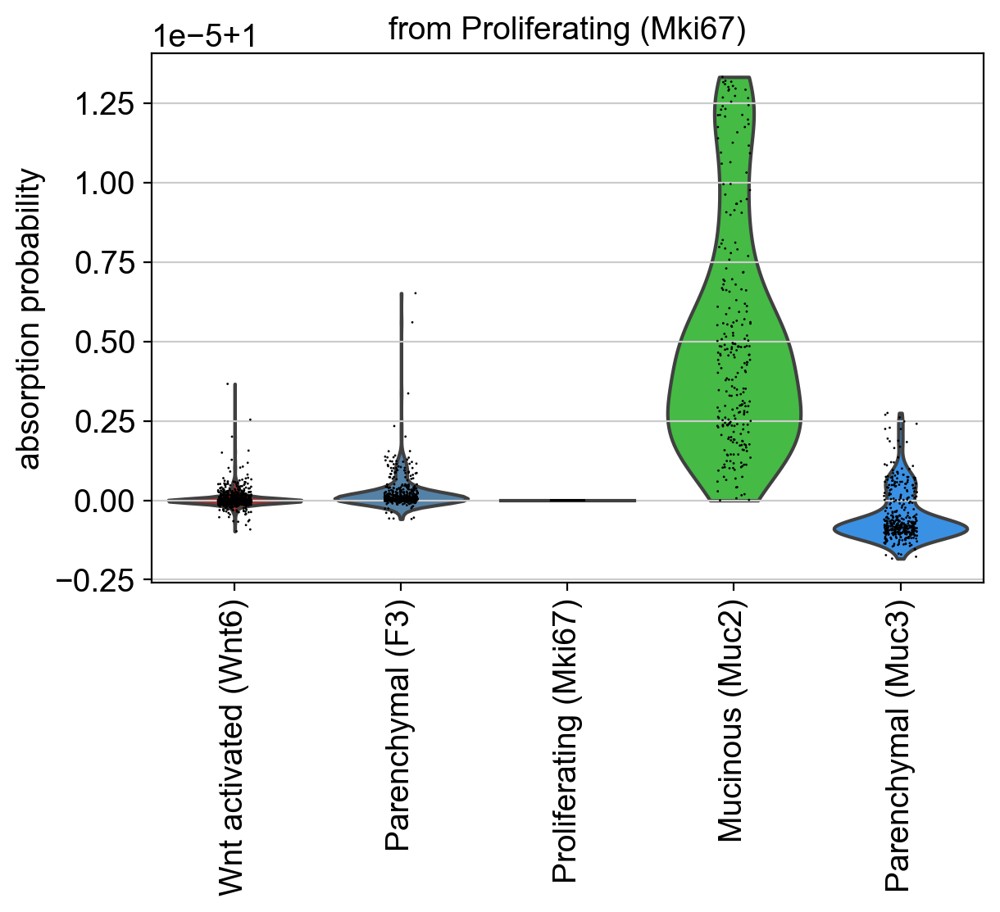

In [43]:
cr.pl.cluster_fates(adata, mode="violin", backward=True, cluster_key="leiden")

C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\seaborn\matrix.py:302: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  mesh = ax.pcolormesh(self.plot_data, cmap=self.cmap, **kws)
C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\seaborn\matrix.py:312: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = ax.figure.colorbar(mesh, cax, ax, **self.cbar_kws)


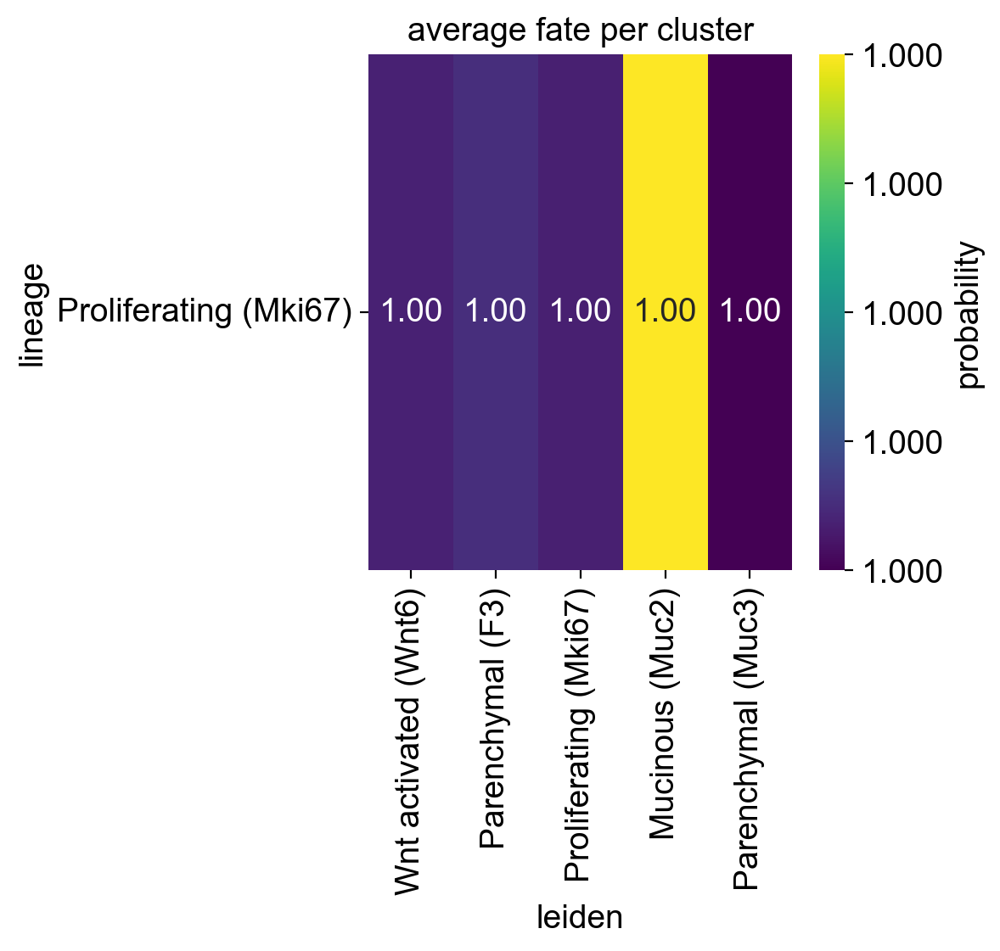

In [44]:
cr.pl.cluster_fates(adata, mode="heatmap", backward=True, cluster_key="leiden")

ValueError: The number of observations cannot be determined on an empty distance matrix.

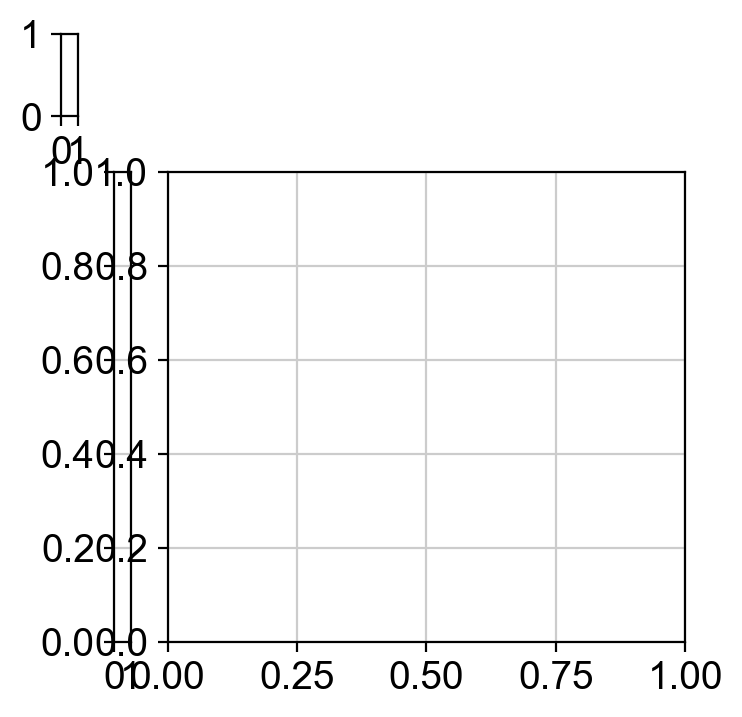

In [45]:
cr.pl.cluster_fates(adata, mode="clustermap", backward=True, cluster_key="leiden")

AnnData object with n_obs × n_vars = 2642 × 2000
    obs: 'predicted_doublets', 'leiden', 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'velocity_length', 'velocity_confidence', 'velocity_confidence_transition', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'clusters_gradients', 'terminal_states', 'terminal_states_probs', 'initial_states'
    var: 'gene_ids', 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes', 'spearmans_score', 'velocity_score'
    uns: 'leiden_colors', 'leiden_sizes', 'neighbors', 'paga', 'pca', 'rank_dynamical_genes', 'rank_velocity_genes',

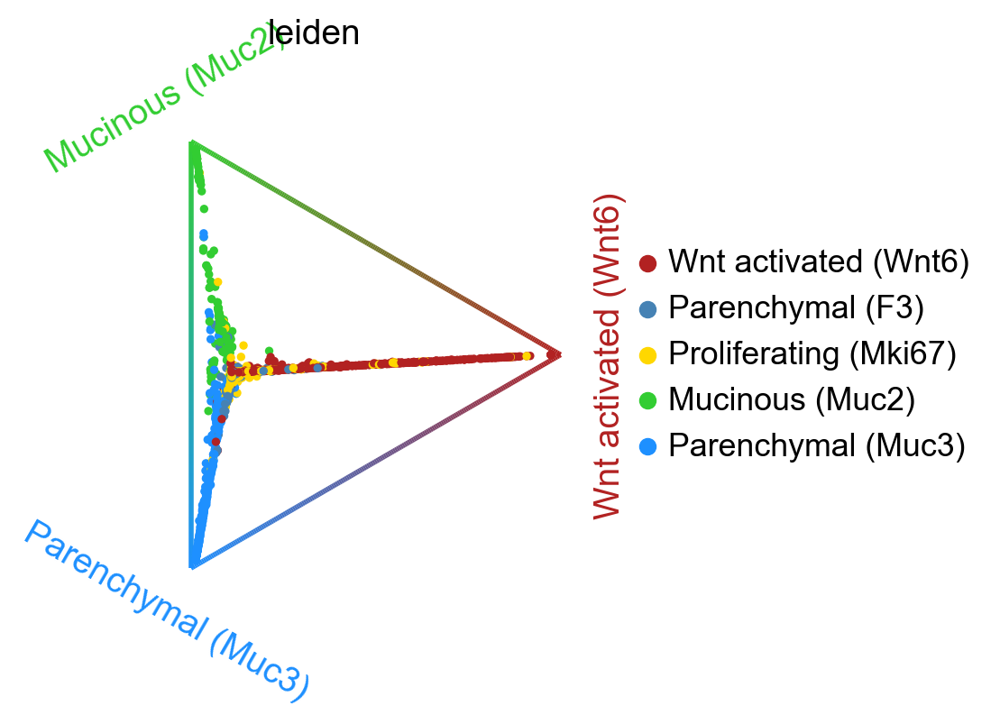

In [46]:
# 5. Fate circular map
cr.pl.circular_projection(adata, keys="leiden", legend_loc="right", save='3.pdf')
# this map arrangs the terminal states around the unit circle and placing initial cells inside
# also you can check the plot function you want at API (https://cellrank.readthedocs.io/en/stable/api.html)
adata
# these codes return
# obsm: 'X_fate_simplex_fwd'

In [ ]:
adata.obs["initial_states"]

In [ ]:
# 6. Check whether DPT, velocity pseudotime and latent time are consistent with CellRank determined fate
root_idx = np.where(adata.obs["initial_states"] == "Proliferating (Mki67)")[0][0]
adata.uns["iroot"] = root_idx
sc.tl.dpt(adata)
adata
# these codes should return, but the dataset is already DPT pseudotime proceed, so no additional values are return
# obs: 'dpt_pseudotime'
# uns: 'iroot', 'diffmap_evals'
# obsm: 'X_diffmap'

In [ ]:
# these 3 pseudotime maps should be consistent with CellRank fate
scv.pl.scatter(adata, color=["leiden", root_idx, "velocity_pseudotime", "latent_time", "dpt_pseudotime"],
               cmap="viridis", perc=[2, 98], colorbar=True, rescale_color=[0, 1], title=["leiden", "root cell", "velocity_pseudotime", "latent_time", "dpt_pseudotime"])

In [ ]:
# 7. Gene expression trends, use the computed probabilities to smooth gene expression trends (pseudotime) along lineages
model = cr.ul.models.GAM(adata)    # should run this first

In [ ]:
# 7.1 gene trends for terminal states (backward=False)
adata.varm['terminal_lineage_drivers'].sort_values(by="Mucinous (Muc2)_corr", ascending=False)

In [ ]:
# plot dynamics of genes in latent time along individual trajectories
cr.pl.gene_trends(adata, model, data_key="X", genes=["Agr2", "Muc2", "Lyz1"], time_key="latent_time", same_plot=True, hide_cells=True, n_test_points=200, backward=False, n_jobs=8)

In [ ]:
# visualize the lineage drivers in a flow heatmap
# use Alpha terminal lineage for example, we smooth gene expression for the putative Alpha-drivers in pseudotime, using cell-level weights the Alpha fate probabilities
cr.pl.heatmap(adata, model, genes=adata.varm['terminal_lineage_drivers']["Mucinous (Muc2)_corr"].sort_values(ascending=False).index[:50], lineages="Mucinous (Muc2)",
              time_key="latent_time", show_absorption_probabilities=True, show_all_genes=False, n_jobs=8, backend="loky", backward=False)    # too many n_jobs kills this step

In [ ]:
# also can draw with self defined genes
cr.pl.heatmap(adata, model, genes=["Agr2", "Muc2", "Lyz1"], lineages="Mucinous (Muc2)",
              time_key="latent_time", show_absorption_probabilities=True, show_all_genes=False, n_jobs=8, backend="loky", backward=False)    # too many n_jobs kills this step

In [ ]:
# plot trends of specific gene across lineages
cr.pl.heatmap(adata, model, genes=["Agr2", "Muc2", "Lyz1"], mode='genes',
              time_key="latent_time", show_all_genes=False, n_jobs=8, backend="loky", backward=False)    # too many n_jobs kills this step

In [ ]:
# plot 'Alpha' lineage genes across clusters
cr.pl.cluster_lineage(adata, model, genes=adata.varm['terminal_lineage_drivers']["Mucinous (Muc2)_corr"].sort_values(ascending=False).index, lineage="Mucinous (Muc2)",
                      time_key="latent_time", n_jobs=8, backward=False)

In [ ]:
adata.uns["lineage_Mucinous (Muc2)_trend"].obs["clusters"]

In [ ]:
# 7.2 gene trends for initial states (backward=True)
adata.varm['initial_lineage_drivers'].sort_values(by="Proliferating (Mki67)_corr", ascending=False)

In [ ]:
# plot dynamics of genes in latent time along individual trajectories
cr.pl.gene_trends(adata, model, data_key="X", genes=["Mki67"], time_key="latent_time", same_plot=True, hide_cells=True, n_test_points=200, backward=True, n_jobs=8)

In [ ]:
# visualize the lineage drivers in a flow heatmap
cr.pl.heatmap(adata, model, genes=adata.varm['initial_lineage_drivers']["Proliferating (Mki67)_corr"].sort_values(ascending=True).index[:50], lineages="Proliferating (Mki67)",
              time_key="latent_time", show_absorption_probabilities=True, show_all_genes=True, n_jobs=8, backend="loky", backward=True)    # too many n_jobs kills this step

In [ ]:
# also can draw with self defined genes
cr.pl.heatmap(adata, model, genes=['Mki67'], lineages="Proliferating (Mki67)",
              time_key="latent_time", show_absorption_probabilities=True, show_all_genes=True, n_jobs=8, backend="loky", backward=True)    # too many n_jobs kills this step

In [ ]:
# plot trends of specific gene across lineages
cr.pl.heatmap(adata, model, genes=['Mki67'], mode='genes',
              time_key="latent_time", show_all_genes=False, n_jobs=8, backend="loky", backward=True)    # too many n_jobs kills this step

In [ ]:
# plot 'Ngn3 low EP' lineage genes across clusters
cr.pl.cluster_lineage(adata, model, genes=adata.varm['initial_lineage_drivers']["Proliferating (Mki67)_corr"].sort_values(ascending=True).index, lineage="Proliferating (Mki67)",
                      time_key="latent_time", n_jobs=8, backward=True)

In [ ]:
adata.uns['lineage_Proliferating (Mki67)_trend'].obs["clusters"]